# Bike Sharing and Urban Micro-Mobility — Data Preprocessing, Correlation, and Regression Analysis

**Lab Assignment No. 6: Analyze Correlation and Regression on Project Dataset**

### Project Overview and Objectives
This notebook demonstrates a rigorous data analytics workflow using a Citi Bike trip-history dataset from January 2025 to June 2025. In urban planning and micro-mobility management, understanding user behavior, trip duration, and spatial-temporal patterns is key to optimizing fleet deployment and station capacity.

Our primary objectives for this assignment are:
1. **Data Preprocessing & Cleaning**: Systematically identify, document, and handle missing values, duplicates, outliers, coordinate errors, and invalid trip durations while preserving original raw data in `df_raw` and keeping an explicit cleaning audit log.
2. **Exploratory Data Analysis**: Visualize distributions and trends across temporal patterns and user categories, including day of week.
3. **Correlation Analysis**: Evaluate linear (Pearson) and monotonic (Spearman) relationships among key variables with appropriate statistical significance tests, keeping coordinate and temporal limitations in mind.
4. **Regression Modeling**: Fit and evaluate a Multiple Linear Regression model predicting `RideDurationMinutes`, validating model assumptions through detailed residual diagnostics.

## Part 1: Introduction and Dataset Loading

We will begin by importing the necessary Python libraries, checking the active directory, and safely loading the dataset `/content/citibike_jan_jun_2025_combined.csv`.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files

# Configure visualizations
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Source file path
file_path = '/content/citibike_jan_jun_2025_combined.csv'

# Load the dataset
if os.path.exists(file_path):
    print(f"File found: {file_path}. Loading data...")
    df_raw = pd.read_csv(file_path, low_memory=False)
    print("Dataset successfully loaded!")
else:
    print(f"Error: File not found at {file_path}. Please check your files tab.")
    # Fallback/upload widget just in case
    uploaded = files.upload()
    for fn in uploaded.keys():
        if fn.endswith('.csv'):
            df_raw = pd.read_csv(fn, low_memory=False)
            print(f"Loaded uploaded file: {fn}")

File found: /content/citibike_jan_jun_2025_combined.csv. Loading data...
Dataset successfully loaded!


## Part 2: Initial Data Profiling

Before modifying or cleaning the dataset, we must profile the raw dataset and establish a baseline data-quality summary.

In [ ]:
print("=== Dataset Dimensions ===")
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")

print("\n=== Column Data Types ===")
print(df_raw.dtypes)

print("\n=== Memory Usage ===")
print(df_raw.info(memory_usage='deep'))

print("\n=== First 5 Rows ===")
display(df_raw.head())

=== Dataset Dimensions ===
Rows: 441,063
Columns: 14

=== Column Data Types ===
ride_id                object
rideable_type          object
started_at             object
ended_at               object
start_station_name     object
start_station_id       object
end_station_name       object
end_station_id         object
start_lat             float64
start_lng             float64
end_lat               float64
end_lng               float64
member_casual          object
source_month            int64
dtype: object

=== Memory Usage ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 441063 entries, 0 to 441062
Data columns (total 14 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             441063 non-null  object 
 1   rideable_type       441063 non-null  object 
 2   started_at          441063 non-null  object 
 3   ended_at            441063 non-null  object 
 4   start_station_name  441062 non-null  object 
 5 

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,source_month
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member,202501
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member,202501
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,202501
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,202501
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,202501


## Initial Data-Quality Checks (continued)

This section quantifies missingness, duplicate records, and coordinate/station completeness before cleaning.


In [ ]:
import pandas as pd
import numpy as np

# 1. Missing-value counts and percentages
missing_counts = df_raw.isnull().sum()
missing_pct = (missing_counts / len(df_raw)) * 100
missing_df = pd.DataFrame({'Missing Counts': missing_counts, 'Percentage (%)': missing_pct})
print("=== Missing Values Profile ===")
display(missing_df)

# 2. Duplicate rows
exact_duplicates = df_raw.duplicated().sum()
print(f"\nExact duplicate rows: {exact_duplicates:,}")

# 3. Duplicate ride_id count
ride_id_duplicates = df_raw.duplicated(subset=['ride_id']).sum()
print(f"Duplicate 'ride_id' values: {ride_id_duplicates:,}")

# Investigate missing end coordinates and station names
missing_end_coords = df_raw['end_lat'].isnull().sum()
missing_end_station = df_raw['end_station_name'].isnull().sum()
print(f"Rows missing end coordinates: {missing_end_coords:,} ({missing_end_coords/len(df_raw)*100:.3f}%)")
print(f"Rows missing end station name: {missing_end_station:,} ({missing_end_station/len(df_raw)*100:.3f}%)")

=== Missing Values Profile ===


,Missing Counts,Percentage (%)
ride_id,0,0.000000
rideable_type,0,0.000000
started_at,0,0.000000
ended_at,0,0.000000
start_station_name,1,0.000227
start_station_id,1,0.000227
end_station_name,1200,0.272070
end_station_id,1425,0.323083
start_lat,0,0.000000
start_lng,0,0.000000



Exact duplicate rows: 0
Duplicate 'ride_id' values: 0
Rows missing end coordinates: 475 (0.108%)
Rows missing end station name: 1,200 (0.272%)


In [ ]:
# Print sample rows that contain missing column values
rows_with_nan = df_raw[df_raw.isnull().any(axis=1)]
print(f"Total rows containing at least one missing value: {len(rows_with_nan):,}")

print("\n=== Sample of 5 rows with missing values ===")
display(rows_with_nan.head(5))

Total rows containing at least one missing value: 1,426

=== Sample of 5 rows with missing values ===


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,source_month
151,068853B69B6D20D0,electric_bike,2025-01-05 16:38:16.142,2025-01-05 16:42:09.995,4 St & River St,HB611,11 St & Washington St,NaN,40.740814,-74.027406,40.75,-74.03,casual,202501
657,58E761514B551292,electric_bike,2025-01-15 05:59:46.181,2025-01-15 06:05:26.636,River St & 1 St,HB609,Newport PATH,NaN,40.737215,-74.028865,40.73,-74.03,member,202501
2118,E6B9FF18F6A1A0D3,electric_bike,2025-01-29 13:34:31.082,2025-01-29 14:36:52.637,York St & Marin Blvd,JC097,NaN,NaN,40.716615,-74.042412,40.72,-74.04,member,202501
2317,9020930B3ACD181D,classic_bike,2025-01-17 13:23:26.471,2025-01-18 14:23:20.918,Hilltop,JC019,NaN,NaN,40.731169,-74.057574,NaN,NaN,member,202501
2318,029CE359525BD2CB,electric_bike,2025-01-17 08:12:54.168,2025-01-17 08:18:29.246,6 St & Grand St,HB302,NaN,NaN,40.744398,-74.034501,40.74,-74.03,member,202501


In [ ]:
# 4. Unique-value counts for categorical columns
categorical_cols = ['rideable_type', 'member_casual']
print("=== Categorical Values Profile ===")
for col in categorical_cols:
    if col in df_raw.columns:
        print(f"\nUnique values in '{col}': {df_raw[col].nunique()}")
        print(df_raw[col].value_counts(dropna=False))

# 5. Coordinate ranges
coord_cols = ['start_lat', 'start_lng', 'end_lat', 'end_lng']
print("\n=== Coordinate Profile ===")
display(df_raw[coord_cols].describe())

=== Categorical Values Profile ===

Unique values in 'rideable_type': 2
rideable_type
electric_bike    281620
classic_bike     159443
Name: count, dtype: int64

Unique values in 'member_casual': 2
member_casual
member    349790
casual     91273
Name: count, dtype: int64

=== Coordinate Profile ===


,start_lat,start_lng,end_lat,end_lng
count,441063.000000,441063.000000,440588.000000,440588.000000
mean,40.732371,-74.040458,40.732304,-74.040190
std,0.012143,0.012164,0.012198,0.012236
min,40.706575,-74.086701,40.620000,-74.150000
25%,40.721525,-74.045953,40.721124,-74.045572
50%,40.735208,-74.037977,40.735208,-74.037977
75%,40.742258,-74.030970,40.742258,-74.030970
max,40.754530,-74.024020,40.849972,-73.924963


## Part 3: Data Preprocessing

We will now execute a rigorous preprocessing pipeline on a separate copy of the data, updating an audit log step-by-step. Let's first separate the duration anomaly investigations and explicitly clean coordinates.

**Station metadata recovery policy:** before dropping incomplete records, the notebook builds a station reference from rows with known station names, IDs, and coordinates. It fills missing IDs from unique names, names from unique IDs, station fields from uniquely identifying coordinates (including conservative two-decimal matching only when that coordinate cell contains one station), and missing coordinates from a station ID with one consistent location. Any ambiguous match is left missing. After duration filtering, `dropna()` excludes rows that still have missing values, and the audit log reports both recovered values and removed rows.


In [ ]:
# 1. Create a working copy of raw data; never modify df_raw.
df_clean = df_raw.copy()
initial_rows = len(df_clean)

# Every cleaning action is logged with row effects and (where relevant) values recovered.
cleaning_log = []

def log_step(step_name, rows_before, rows_after, explanation, values_recovered=0):
    cleaning_log.append({
        'Step': step_name,
        'Rows Before': int(rows_before),
        'Rows After': int(rows_after),
        'Rows Removed': int(rows_before - rows_after),
        'Values Recovered': int(values_recovered),
        'Reason / Details': explanation
    })
    print(
        f"[LOG] {step_name}: rows {rows_before:,} -> {rows_after:,}; "
        f"rows removed={rows_before - rows_after:,}; values recovered={values_recovered:,}"
    )


In [ ]:
# 2. Standardize column names
bef = len(df_clean)
df_clean.columns = df_clean.columns.str.strip()
log_step("Standardize Column Names", bef, len(df_clean), "Stripped whitespace from column headers")

[LOG] Standardize Column Names: rows 441,063 -> 441,063; rows removed=0; values recovered=0


In [ ]:
# Parse timestamps and convert coordinates to numeric before validation.
bef = len(df_clean)
df_clean['started_at'] = pd.to_datetime(df_clean['started_at'], errors='coerce')
df_clean['ended_at'] = pd.to_datetime(df_clean['ended_at'], errors='coerce')

coord_cols = ['start_lat', 'start_lng', 'end_lat', 'end_lng']
for col in coord_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

station_fields_and_coords = [
    'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id',
    'start_lat', 'start_lng', 'end_lat', 'end_lng'
]
original_missing_masks = {
    col: df_clean[col].isna().copy()
    for col in station_fields_and_coords
}

# Standardize station text/IDs for matching, without changing the original raw dataframe.
for col in ['start_station_name', 'end_station_name']:
    df_clean[col] = df_clean[col].astype('string').str.strip()
for col in ['start_station_id', 'end_station_id']:
    df_clean[col] = df_clean[col].astype('string').str.strip()

invalid_timestamp_rows = int(df_clean[['started_at', 'ended_at']].isna().any(axis=1).sum())
print(f"Rows with a missing/unparseable start or end timestamp: {invalid_timestamp_rows:,}")
print("Missing values before station recovery:")
display(df_clean[['start_station_name', 'start_station_id', 'end_station_name',
                  'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng']].isna().sum().to_frame('missing_count'))

# Build a station reference from rows where station name, ID, and coordinates are all present.
# Both trip-start and trip-end records contribute to the reference.
station_parts = []
for side in ['start', 'end']:
    part = df_clean[[f'{side}_station_name', f'{side}_station_id',
                     f'{side}_lat', f'{side}_lng']].copy()
    part.columns = ['station_name', 'station_id', 'lat', 'lng']
    station_parts.append(part)

station_registry = pd.concat(station_parts, ignore_index=True).dropna(
    subset=['station_name', 'station_id', 'lat', 'lng']
).drop_duplicates().copy()

station_registry['name_key'] = (
    station_registry['station_name'].astype('string').str.strip().str.casefold()
    .str.replace(r'\s+', ' ', regex=True)
)
station_registry['id_key'] = station_registry['station_id'].astype('string').str.strip()
station_registry['coord_key'] = list(zip(station_registry['lat'], station_registry['lng']))
station_registry['rounded_coord_key'] = list(zip(
    station_registry['lat'].round(2), station_registry['lng'].round(2)
))

def make_unique_lookup(frame, key_col, value_col):
    distinct = frame[[key_col, value_col]].dropna().drop_duplicates()
    counts = distinct.groupby(key_col)[value_col].nunique()
    valid_keys = counts[counts == 1].index
    return distinct[distinct[key_col].isin(valid_keys)].drop_duplicates(key_col).set_index(key_col)[value_col].to_dict()

name_to_id = make_unique_lookup(station_registry, 'name_key', 'id_key')
id_to_name = make_unique_lookup(station_registry, 'id_key', 'station_name')
id_to_coords = make_unique_lookup(
    station_registry.assign(coord_pair=list(zip(station_registry['lat'], station_registry['lng']))),
    'id_key', 'coord_pair'
)

# Coordinate-to-station mappings are permitted only when the coordinates identify
# exactly one station in the reference. Rounded-coordinate matching is conservative:
# it is attempted only when both observed coordinates are rounded to 2 decimals.
exact_coord_counts = station_registry.groupby('coord_key').agg(
    n_names=('name_key', 'nunique'), n_ids=('id_key', 'nunique')
)
unique_exact_coords = exact_coord_counts[
    (exact_coord_counts['n_names'] == 1) & (exact_coord_counts['n_ids'] == 1)
].index
exact_registry = station_registry[station_registry['coord_key'].isin(unique_exact_coords)].drop_duplicates('coord_key')
coord_to_name = exact_registry.set_index('coord_key')['station_name'].to_dict()
coord_to_id = exact_registry.set_index('coord_key')['id_key'].to_dict()

rounded_coord_counts = station_registry.groupby('rounded_coord_key').agg(
    n_names=('name_key', 'nunique'), n_ids=('id_key', 'nunique')
)
unique_rounded_coords = rounded_coord_counts[
    (rounded_coord_counts['n_names'] == 1) & (rounded_coord_counts['n_ids'] == 1)
].index
rounded_registry = station_registry[
    station_registry['rounded_coord_key'].isin(unique_rounded_coords)
].drop_duplicates('rounded_coord_key')
rounded_coord_to_name = rounded_registry.set_index('rounded_coord_key')['station_name'].to_dict()
rounded_coord_to_id = rounded_registry.set_index('rounded_coord_key')['id_key'].to_dict()

station_recovery_counts = {}

# A. Recover missing station IDs from an existing station name, but only when the
# normalized name maps to exactly one ID in the reference.
for side in ['start', 'end']:
    name_col, id_col = f'{side}_station_name', f'{side}_station_id'
    missing_id = df_clean[name_col].notna() & df_clean[id_col].isna()
    name_keys = (
        df_clean.loc[missing_id, name_col].astype('string').str.strip().str.casefold()
        .str.replace(r'\s+', ' ', regex=True)
    )
    mapped_ids = name_keys.map(name_to_id)
    fill_mask = mapped_ids.notna()
    df_clean.loc[mapped_ids.index[fill_mask], id_col] = mapped_ids[fill_mask]
    recovered = int(fill_mask.sum())
    station_recovery_counts[f'{side}_id_from_unique_name'] = recovered
    log_step(f"Recover {side} station ID from unique station name", len(df_clean), len(df_clean),
             "Filled only when the normalized station name maps to exactly one known station ID.",
             values_recovered=recovered)

# B. Recover a missing station name from a known ID only when that ID has one name.
for side in ['start', 'end']:
    name_col, id_col = f'{side}_station_name', f'{side}_station_id'
    missing_name = df_clean[name_col].isna() & df_clean[id_col].notna()
    id_keys = df_clean.loc[missing_name, id_col].astype('string').str.strip()
    mapped_names = id_keys.map(id_to_name)
    fill_mask = mapped_names.notna()
    df_clean.loc[mapped_names.index[fill_mask], name_col] = mapped_names[fill_mask]
    recovered = int(fill_mask.sum())
    station_recovery_counts[f'{side}_name_from_unique_id'] = recovered
    log_step(f"Recover {side} station name from unique station ID", len(df_clean), len(df_clean),
             "Filled only when the station ID maps to exactly one known station name.",
             values_recovered=recovered)

# C. Recover missing station name/ID from exact coordinates when the coordinate pair
# uniquely identifies one station in the reference.
for side in ['start', 'end']:
    name_col, id_col = f'{side}_station_name', f'{side}_station_id'
    lat_col, lng_col = f'{side}_lat', f'{side}_lng'
    coord_keys = pd.Series(
        list(zip(df_clean[lat_col], df_clean[lng_col])), index=df_clean.index
    )
    mapped_names = coord_keys.map(coord_to_name)
    mapped_ids = coord_keys.map(coord_to_id)
    name_mask = df_clean[name_col].isna() & mapped_names.notna()
    id_mask = df_clean[id_col].isna() & mapped_ids.notna()
    df_clean.loc[name_mask, name_col] = mapped_names[name_mask]
    df_clean.loc[id_mask, id_col] = mapped_ids[id_mask]
    recovered = int(name_mask.sum() + id_mask.sum())
    station_recovery_counts[f'{side}_station_fields_from_exact_coordinates'] = recovered
    log_step(f"Recover {side} station fields from unique exact coordinates", len(df_clean), len(df_clean),
             "Used exact latitude/longitude only where the coordinate pair maps to one station.",
             values_recovered=recovered)

# D. Some missing station metadata has coordinates rounded to two decimal places.
# Use those coordinates only if the rounded cell contains exactly one known station.
for side in ['start', 'end']:
    name_col, id_col = f'{side}_station_name', f'{side}_station_id'
    lat_col, lng_col = f'{side}_lat', f'{side}_lng'
    lat_values, lng_values = df_clean[lat_col], df_clean[lng_col]
    rounded_input = (
        lat_values.notna() & lng_values.notna()
        & np.isclose(lat_values, lat_values.round(2))
        & np.isclose(lng_values, lng_values.round(2))
    )
    rounded_keys = pd.Series(
        list(zip(lat_values.round(2), lng_values.round(2))), index=df_clean.index
    )
    mapped_names = rounded_keys.map(rounded_coord_to_name)
    mapped_ids = rounded_keys.map(rounded_coord_to_id)
    name_mask = df_clean[name_col].isna() & mapped_names.notna() & rounded_input
    id_mask = df_clean[id_col].isna() & mapped_ids.notna() & rounded_input
    df_clean.loc[name_mask, name_col] = mapped_names[name_mask]
    df_clean.loc[id_mask, id_col] = mapped_ids[id_mask]
    recovered = int(name_mask.sum() + id_mask.sum())
    station_recovery_counts[f'{side}_station_fields_from_unique_rounded_coordinates'] = recovered
    log_step(f"Recover {side} station fields from unique rounded coordinates", len(df_clean), len(df_clean),
             "Used two-decimal coordinates only when both values were rounded and the rounded cell maps to exactly one station; ambiguous cells were left missing.",
             values_recovered=recovered)

# E. Recover missing coordinate values from a known station ID only when that ID
# has one consistent coordinate pair in the reference.
for side in ['start', 'end']:
    id_col, lat_col, lng_col = f'{side}_station_id', f'{side}_lat', f'{side}_lng'
    mapped_coords = df_clean[id_col].astype('string').str.strip().map(id_to_coords)
    missing_lat = df_clean[lat_col].isna() & mapped_coords.notna()
    missing_lng = df_clean[lng_col].isna() & mapped_coords.notna()
    if missing_lat.any():
        lat_replacements = mapped_coords.loc[missing_lat].map(lambda x: x[0]).astype(float)
        df_clean.loc[missing_lat, lat_col] = lat_replacements.to_numpy()
    if missing_lng.any():
        lng_replacements = mapped_coords.loc[missing_lng].map(lambda x: x[1]).astype(float)
        df_clean.loc[missing_lng, lng_col] = lng_replacements.to_numpy()
    recovered = int(missing_lat.sum() + missing_lng.sum())
    station_recovery_counts[f'{side}_coordinates_from_unique_station_id'] = recovered
    log_step(f"Recover {side} coordinates from unique station ID", len(df_clean), len(df_clean),
             "Filled missing coordinate values only when the station ID has one consistent coordinate pair.",
             values_recovered=recovered)

print("\\n=== Station metadata recovery summary (values, not rows) ===")
display(pd.DataFrame([
    {'Recovery operation': operation, 'Values recovered': count}
    for operation, count in station_recovery_counts.items()
]))
print("\\nMissing values after station recovery, before duration filtering:")
display(df_clean[['start_station_name', 'start_station_id', 'end_station_name',
                  'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng']].isna().sum().to_frame('missing_count'))

# Invalid timestamps are excluded. Station fields and coordinates are not dropped here:
# first complete all safe recovery attempts, then drop unresolved rows after duration filtering.
df_clean = df_clean.dropna(subset=['started_at', 'ended_at'])
log_step("Parse timestamps and remove invalid timestamps", bef, len(df_clean),
         "Timestamp parsing uses errors='coerce'; rows with missing/unparseable timestamps are excluded.")


Rows with a missing/unparseable start or end timestamp: 0
Missing values before station recovery:


,missing_count
start_station_name,1
start_station_id,1
end_station_name,1200
end_station_id,1425
start_lat,0
start_lng,0
end_lat,475
end_lng,475


[LOG] Recover start station ID from unique station name: rows 441,063 -> 441,063; rows removed=0; values recovered=0
[LOG] Recover end station ID from unique station name: rows 441,063 -> 441,063; rows removed=0; values recovered=225
[LOG] Recover start station name from unique station ID: rows 441,063 -> 441,063; rows removed=0; values recovered=0
[LOG] Recover end station name from unique station ID: rows 441,063 -> 441,063; rows removed=0; values recovered=0
[LOG] Recover start station fields from unique exact coordinates: rows 441,063 -> 441,063; rows removed=0; values recovered=0
[LOG] Recover end station fields from unique exact coordinates: rows 441,063 -> 441,063; rows removed=0; values recovered=0
[LOG] Recover start station fields from unique rounded coordinates: rows 441,063 -> 441,063; rows removed=0; values recovered=0
[LOG] Recover end station fields from unique rounded coordinates: rows 441,063 -> 441,063; rows removed=0; values recovered=132
[LOG] Recover start coordina

,Recovery operation,Values recovered
0,start_id_from_unique_name,0
1,end_id_from_unique_name,225
2,start_name_from_unique_id,0
3,end_name_from_unique_id,0
4,start_station_fields_from_exact_coordinates,0
5,end_station_fields_from_exact_coordinates,0
6,start_station_fields_from_unique_rounded_coord...,0
7,end_station_fields_from_unique_rounded_coordin...,132
8,start_coordinates_from_unique_station_id,0
9,end_coordinates_from_unique_station_id,136


\nMissing values after station recovery, before duration filtering:


,missing_count
start_station_name,1
start_station_id,1
end_station_name,1134
end_station_id,1134
start_lat,0
start_lng,0
end_lat,407
end_lng,407


[LOG] Parse timestamps and remove invalid timestamps: rows 441,063 -> 441,063; rows removed=0; values recovered=0


In [ ]:
# Check and remove exact duplicate rows only if any exist.
bef = len(df_clean)
exact_dupes_here = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
log_step("Check/drop exact duplicate rows", bef, len(df_clean),
         f"Exact duplicate rows detected at this step: {exact_dupes_here:,}; drop_duplicates removes only exact repeats.")

# Check repeated ride IDs; keep one per ride_id only if duplicates exist.
bef_ride_id = len(df_clean)
ride_id_dupes_here = int(df_clean.duplicated(subset=['ride_id']).sum())
df_clean = df_clean.drop_duplicates(subset=['ride_id'], keep='first')
log_step("Check/deduplicate ride_id", bef_ride_id, len(df_clean),
         f"Repeated ride_id rows detected at this step: {ride_id_dupes_here:,}; first occurrence retained only when repeated IDs exist.")


[LOG] Check/drop exact duplicate rows: rows 441,063 -> 441,063; rows removed=0; values recovered=0
[LOG] Check/deduplicate ride_id: rows 441,063 -> 441,063; rows removed=0; values recovered=0


In [ ]:
# Validate coordinate values against global latitude/longitude limits.
# Missing coordinates are retained and reported; only non-missing out-of-range values are excluded.
bef = len(df_clean)
coord_invalid_mask = (
    (df_clean['start_lat'].notna() & ~df_clean['start_lat'].between(-90, 90)) |
    (df_clean['start_lng'].notna() & ~df_clean['start_lng'].between(-180, 180)) |
    (df_clean['end_lat'].notna() & ~df_clean['end_lat'].between(-90, 90)) |
    (df_clean['end_lng'].notna() & ~df_clean['end_lng'].between(-180, 180))
)
invalid_coordinate_rows = int(coord_invalid_mask.sum())
print(f"Rows with non-missing, globally out-of-range coordinates: {invalid_coordinate_rows:,}")

df_clean = df_clean.loc[~coord_invalid_mask].copy()
log_step("Validate coordinate ranges", bef, len(df_clean),
         "Removed only rows with non-missing coordinates outside global latitude/longitude bounds; missing coordinates are retained for non-spatial analyses.")


Rows with non-missing, globally out-of-range coordinates: 0
[LOG] Validate coordinate ranges: rows 441,063 -> 441,063; rows removed=0; values recovered=0


In [ ]:
# Calculate duration, compare positive-duration records with and without the >24-hour cutoff,
# then apply the documented analysis filter.
bef = len(df_clean)
df_clean['RideDurationMinutes'] = (
    (df_clean['ended_at'] - df_clean['started_at']).dt.total_seconds() / 60.0
)

non_positive_count = int((df_clean['RideDurationMinutes'] <= 0).sum())
missing_duration_count = int(df_clean['RideDurationMinutes'].isna().sum())
exceed_24h_count = int((df_clean['RideDurationMinutes'] > 1440).sum())
positive_duration = df_clean['RideDurationMinutes'].gt(0)
positive_all = df_clean.loc[positive_duration, 'RideDurationMinutes']
positive_under_24h = df_clean.loc[positive_duration & df_clean['RideDurationMinutes'].le(1440), 'RideDurationMinutes']

print("=== Duration anomaly counts (before filtering) ===")
print(f"Missing duration: {missing_duration_count:,}")
print(f"Non-positive duration (<= 0 minutes): {non_positive_count:,}")
print(f"Duration > 24 hours: {exceed_24h_count:,}")
print(f"Positive-duration rows before >24-hour exclusion: {len(positive_all):,}")
print(f"Positive-duration rows after >24-hour exclusion: {len(positive_under_24h):,}")

duration_comparison = pd.DataFrame({
    'Positive durations, including >24h': positive_all.describe(percentiles=[.5, .9, .95, .99]),
    'Positive durations, excluding >24h': positive_under_24h.describe(percentiles=[.5, .9, .95, .99])
})
print("\n=== Duration summary with and without the >24-hour exclusion (minutes) ===")
display(duration_comparison.round(3))

# Compare a selected association on the same positive-duration population.
start_hour_for_compare = df_clean.loc[positive_duration, 'started_at'].dt.hour
duration_start_hour_all = pd.concat(
    [positive_all.rename('duration'), start_hour_for_compare.rename('start_hour')], axis=1
).dropna()
duration_start_hour_trim = df_clean.loc[
    positive_duration & df_clean['RideDurationMinutes'].le(1440),
    ['RideDurationMinutes', 'started_at']
].copy()
duration_start_hour_trim['start_hour'] = duration_start_hour_trim['started_at'].dt.hour
print("\nPearson correlation: duration vs numeric start hour (descriptive comparison only)")
if len(duration_start_hour_all) > 1:
    print(f"Including >24h: N={len(duration_start_hour_all):,}, r={duration_start_hour_all['duration'].corr(duration_start_hour_all['start_hour']):.5f}")
if len(duration_start_hour_trim) > 1:
    print(f"Excluding >24h: N={len(duration_start_hour_trim):,}, r={duration_start_hour_trim['RideDurationMinutes'].corr(duration_start_hour_trim['start_hour']):.5f}")

# Analysis decision: exclude non-positive durations and trips over 24 hours.
# The cutoff is a transparent operational rule for the primary analysis, not proof these records are erroneous.
duration_filter = positive_duration & df_clean['RideDurationMinutes'].le(1440)
df_clean = df_clean.loc[duration_filter].copy()
log_step("Exclude non-positive and >24-hour durations", bef, len(df_clean),
         f"Excluded {non_positive_count:,} non-positive, {exceed_24h_count:,} >24-hour, and {missing_duration_count:,} missing-duration rows. The >24-hour cutoff is used for the primary analysis to reduce extreme-duration influence; the comparison above documents its impact.")

# All safe station/name/ID/coordinate recovery attempts have now been made.
# Drop rows that still contain missing values and record the exact row effect.
missing_counts_before_dropna = df_clean.isna().sum()
rows_with_missing_before_dropna = int(df_clean.isna().any(axis=1).sum())
print("=== Missing values before final dropna ===")
display(missing_counts_before_dropna[missing_counts_before_dropna > 0].to_frame('missing_count'))
print(f"Rows containing one or more missing values: {rows_with_missing_before_dropna:,}")

bef_missing = len(df_clean)
df_clean = df_clean.dropna().copy()
log_step("Drop rows with unresolved missing values after station recovery",
         bef_missing, len(df_clean),
         "After safe station-name/ID/coordinate matching, rows with any remaining missing value are excluded. No station identity is guessed for ambiguous coordinate matches.")

# Count recovered values that remain in the final dataset (excluding values recovered
# in rows later removed by the duration filter or final dropna).
station_recovery_counts_final = {}
for col in station_fields_and_coords:
    originally_missing_in_final_rows = original_missing_masks[col].reindex(df_clean.index).fillna(False)
    station_recovery_counts_final[col] = int(
        (originally_missing_in_final_rows & df_clean[col].notna()).sum()
    )
print("\\n=== Recovered values retained in the final cleaned dataset ===")
display(pd.DataFrame([
    {'Column': col, 'Values recovered and retained': count}
    for col, count in station_recovery_counts_final.items()
]))

# Engineer temporal predictors only after duration and missing-value filters.
bef_fe = len(df_clean)
df_clean['StartHour'] = df_clean['started_at'].dt.hour
df_clean['EndHour'] = df_clean['ended_at'].dt.hour
df_clean['DayOfWeek'] = df_clean['started_at'].dt.day_name()
df_clean['StartDayOfWeekNumber'] = df_clean['started_at'].dt.dayofweek
df_clean['Month'] = df_clean['started_at'].dt.month
df_clean['DayOfMonth'] = df_clean['started_at'].dt.day
df_clean['IsWeekend'] = (df_clean['StartDayOfWeekNumber'] >= 5).astype(int)
df_clean['StartHour_sin'] = np.sin(2 * np.pi * df_clean['StartHour'] / 24.0)
df_clean['StartHour_cos'] = np.cos(2 * np.pi * df_clean['StartHour'] / 24.0)
log_step("Feature engineering", bef_fe, len(df_clean),
         "Created hour, weekday, month, weekend, and cyclical start-hour features; no rows removed.")


=== Duration anomaly counts (before filtering) ===
Missing duration: 0
Non-positive duration (<= 0 minutes): 0
Duration > 24 hours: 132
Positive-duration rows before >24-hour exclusion: 441,063
Positive-duration rows after >24-hour exclusion: 440,931

=== Duration summary with and without the >24-hour exclusion (minutes) ===


,"Positive durations, including >24h","Positive durations, excluding >24h"
count,441063.000,440931.000
mean,9.594,9.139
std,35.183,22.507
min,1.002,1.002
50%,5.820,5.819
90%,15.527,15.502
95%,23.594,23.517
99%,59.686,58.836
max,5656.054,1429.577



Pearson correlation: duration vs numeric start hour (descriptive comparison only)
Including >24h: N=441,063, r=0.01064
Excluding >24h: N=440,931, r=0.02001
[LOG] Exclude non-positive and >24-hour durations: rows 441,063 -> 440,931; rows removed=132; values recovered=0
=== Missing values before final dropna ===


,missing_count
start_station_name,1
start_station_id,1
end_station_name,1008
end_station_id,1008
end_lat,287
end_lng,287


Rows containing one or more missing values: 1,009
[LOG] Drop rows with unresolved missing values after station recovery: rows 440,931 -> 439,922; rows removed=1,009; values recovered=0
\n=== Recovered values retained in the final cleaned dataset ===


,Column,Values recovered and retained
0,start_station_name,0
1,start_station_id,0
2,end_station_name,65
3,end_station_id,290
4,start_lat,0
5,start_lng,0
6,end_lat,68
7,end_lng,68


[LOG] Feature engineering: rows 439,922 -> 439,922; rows removed=0; values recovered=0


In [ ]:
# 7. Categorical Standardisation
bef = len(df_clean)
df_clean['rideable_type'] = df_clean['rideable_type'].str.strip()
df_clean['member_casual'] = df_clean['member_casual'].str.strip()
log_step("Standardize Categories", bef, len(df_clean), "Trimmed white spaces from rideable_type and member_casual")

[LOG] Standardize Categories: rows 439,922 -> 439,922; rows removed=0; values recovered=0


In [ ]:
# 8. Feature verification step
print("=== Preprocessed Columns and Verification ===")
verification_cols = ['RideDurationMinutes', 'StartHour', 'IsWeekend', 'StartHour_sin', 'StartHour_cos']
print(df_clean[verification_cols].head())

=== Preprocessed Columns and Verification ===
   RideDurationMinutes  StartHour  IsWeekend  StartHour_sin  StartHour_cos
0             6.192900         17          0      -0.965926  -2.588190e-01
1            11.461350          6          0       1.000000   6.123234e-17
2            21.377617         16          0      -0.866025  -5.000000e-01
3            22.934333         16          0      -0.866025  -5.000000e-01
4            25.822100         16          0      -0.866025  -5.000000e-01


In [ ]:
print(f"Final cleaned dataset shape: {df_clean.shape}")


Final cleaned dataset shape: (439922, 24)


In [ ]:
# Final validation: missingness and numeric summaries.
cleaning_log_df = pd.DataFrame(cleaning_log)
print("=== Final Cleaning Audit Log ===")
display(cleaning_log_df)

print("\n=== Remaining missing values by column ===")
display(df_clean.isna().sum().rename('missing_count').to_frame())

print("\n=== Final numeric descriptive statistics ===")
display(df_clean.describe(include='number').T)
print(f"\nRows before cleaning: {len(df_raw):,}")
print(f"Rows after cleaning:  {len(df_clean):,}")
print(f"Net rows excluded:    {len(df_raw) - len(df_clean):,}")


=== Final Cleaning Audit Log ===


,Step,Rows Before,Rows After,Rows Removed,Values Recovered,Reason / Details
0,Standardize Column Names,441063,441063,0,0,Stripped whitespace from column headers
1,Recover start station ID from unique station name,441063,441063,0,0,Filled only when the normalized station name m...
2,Recover end station ID from unique station name,441063,441063,0,225,Filled only when the normalized station name m...
3,Recover start station name from unique station ID,441063,441063,0,0,Filled only when the station ID maps to exactl...
4,Recover end station name from unique station ID,441063,441063,0,0,Filled only when the station ID maps to exactl...
5,Recover start station fields from unique exact...,441063,441063,0,0,Used exact latitude/longitude only where the c...
6,Recover end station fields from unique exact c...,441063,441063,0,0,Used exact latitude/longitude only where the c...
7,Recover start station fields from unique round...,441063,441063,0,0,Used two-decimal coordinates only when both va...
8,Recover end station fields from unique rounded...,441063,441063,0,132,Used two-decimal coordinates only when both va...
9,Recover start coordinates from unique station ID,441063,441063,0,0,Filled missing coordinate values only when the...



=== Remaining missing values by column ===


,missing_count
ride_id,0
rideable_type,0
started_at,0
ended_at,0
start_station_name,0
start_station_id,0
end_station_name,0
end_station_id,0
start_lat,0
start_lng,0



=== Final numeric descriptive statistics ===


,count,mean,std,min,25%,50%,75%,max
start_lat,439922.0,40.732375,0.012140,40.706575,40.721525,40.735208,4.074226e+01,40.754530
start_lng,439922.0,-74.040448,0.012151,-74.086701,-74.045953,-74.037977,-7.403097e+01,-74.024020
end_lat,439922.0,40.732306,0.012188,40.651566,40.721124,40.735208,4.074226e+01,40.849972
end_lng,439922.0,-74.040184,0.012213,-74.090000,-74.045572,-74.037977,-7.403097e+01,-73.924963
source_month,439922.0,202503.935320,1.642392,202501.000000,202503.000000,202504.000000,2.025050e+05,202506.000000
RideDurationMinutes,439922.0,8.975463,21.478050,1.001650,3.848746,5.808908,9.126179e+00,1400.535033
StartHour,439922.0,13.892542,5.061727,0.000000,10.000000,15.000000,1.800000e+01,23.000000
EndHour,439922.0,13.986893,5.092030,0.000000,10.000000,15.000000,1.800000e+01,23.000000
StartDayOfWeekNumber,439922.0,2.932597,1.934344,0.000000,1.000000,3.000000,5.000000e+00,6.000000
Month,439922.0,3.935325,1.642457,1.000000,3.000000,4.000000,5.000000e+00,12.000000



Rows before cleaning: 441,063
Rows after cleaning:  439,922
Net rows excluded:    1,141


## Part 4: Final Data-Quality Validation & Export

In [ ]:
# Export the cleaned data and the final audit log after all cleaning steps.
export_dir = '/content/exports'
os.makedirs(export_dir, exist_ok=True)
cleaned_csv_path = os.path.join(export_dir, 'citibike_jan_jun_2025_cleaned.csv')
cleaning_log_path = os.path.join(export_dir, 'cleaning_log.csv')

df_clean.to_csv(cleaned_csv_path, index=False)
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.to_csv(cleaning_log_path, index=False)

print(f"Cleaned dataset saved: {cleaned_csv_path}")
print(f"Cleaning log saved:    {cleaning_log_path}")


Cleaned dataset saved: /content/exports/citibike_jan_jun_2025_cleaned.csv
Cleaning log saved:    /content/exports/cleaning_log.csv


## Part 5: Exploratory Data Analysis

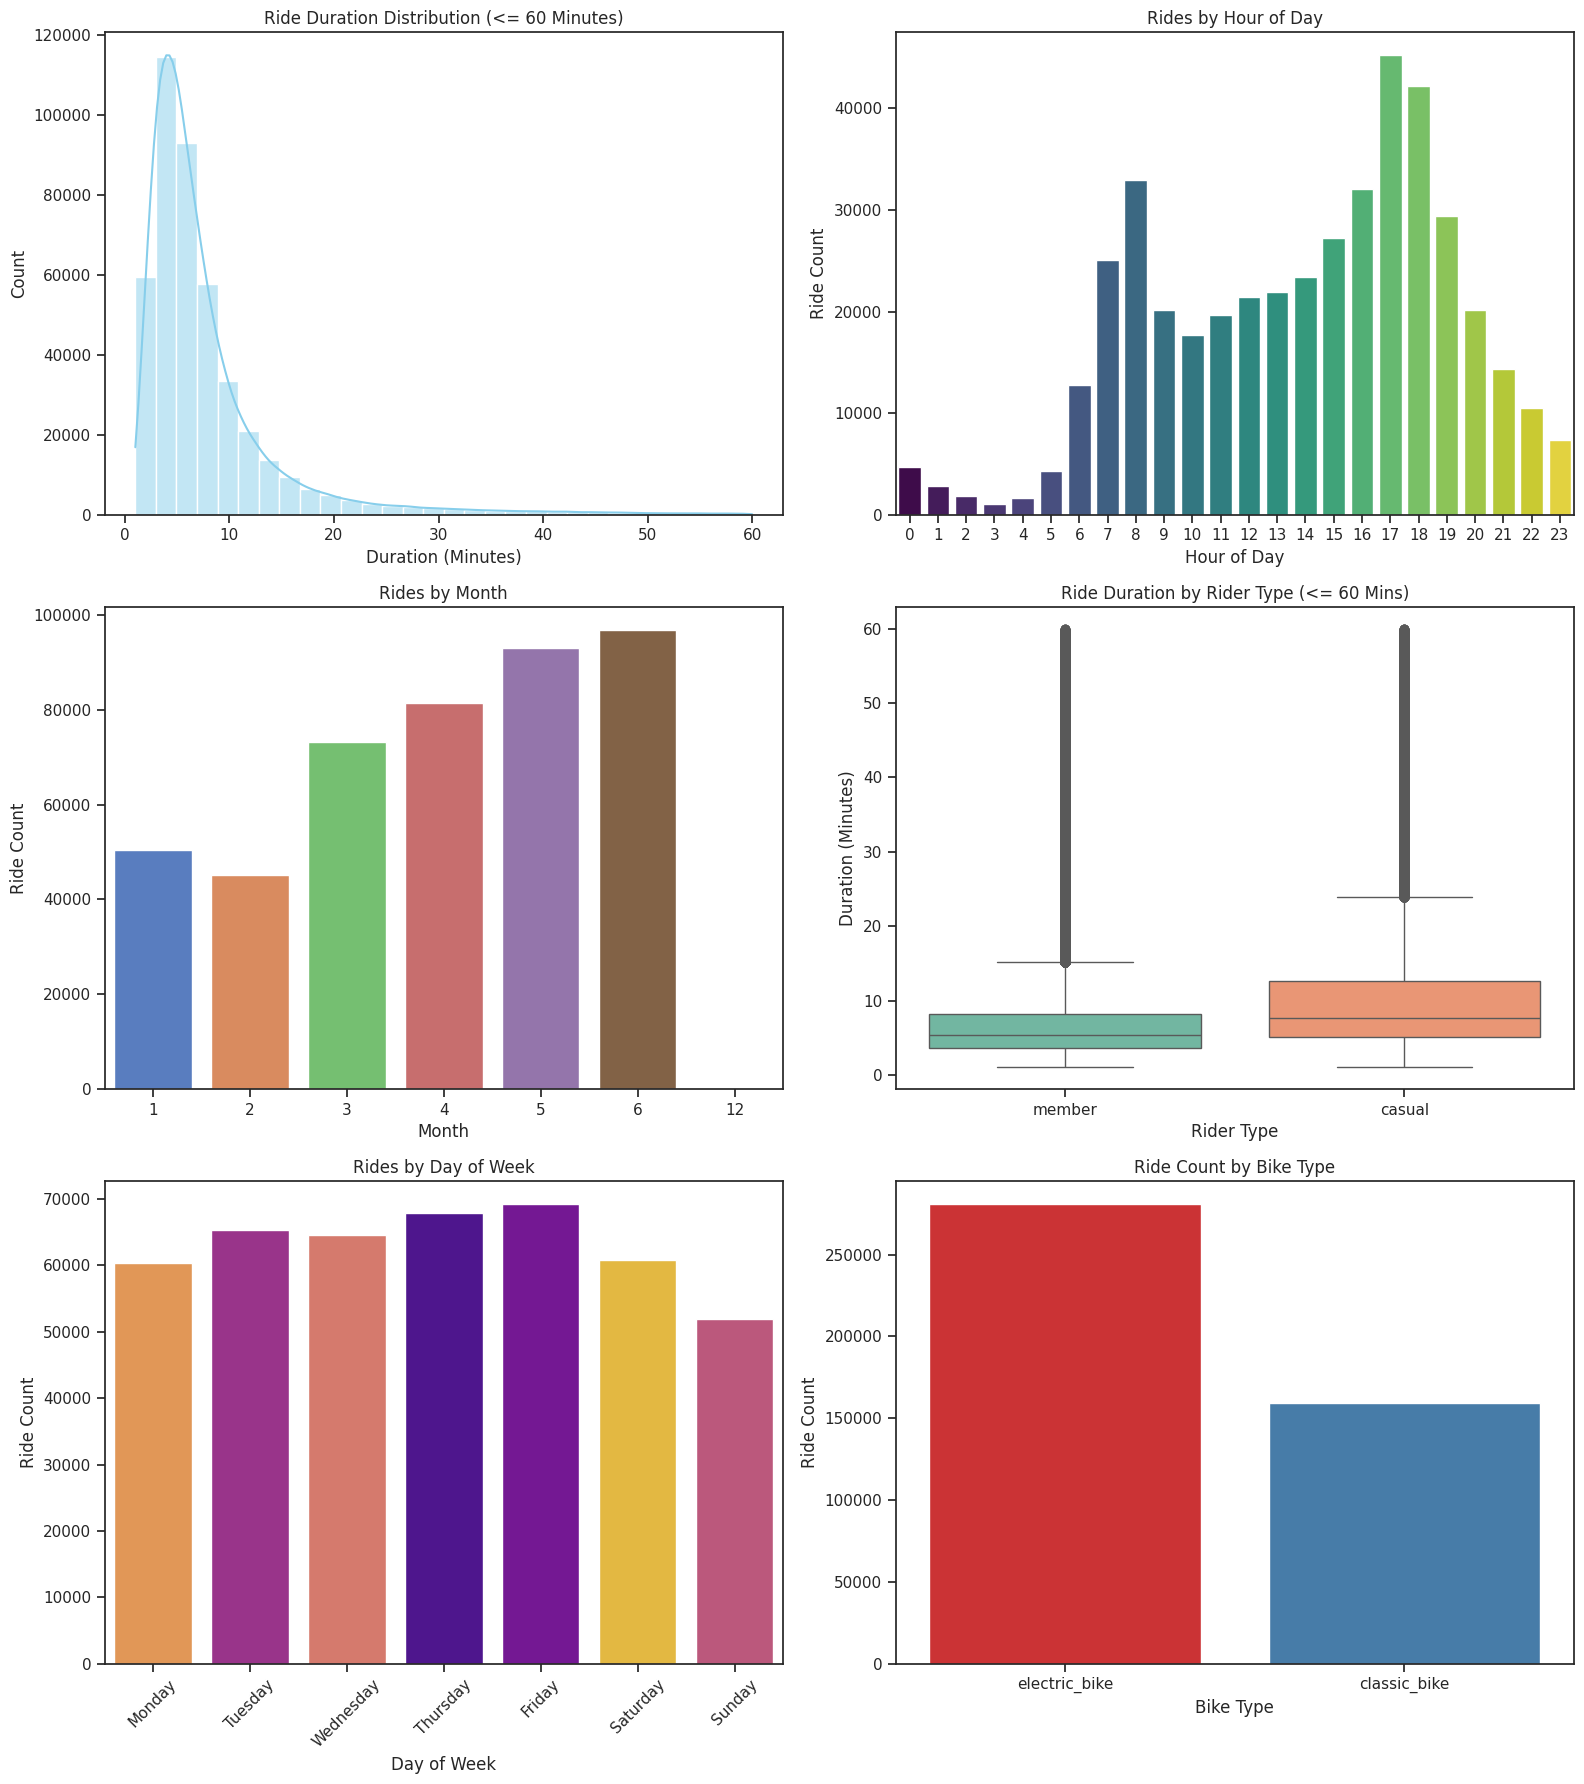

In [ ]:
# Set visualization style
sns.set_style("ticks")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Ride-duration distribution
sns.histplot(df_clean[df_clean['RideDurationMinutes'] <= 60]['RideDurationMinutes'],
             bins=30, kde=True, ax=axes[0,0], color='skyblue')
axes[0,0].set_title('Ride Duration Distribution (<= 60 Minutes)')
axes[0,0].set_xlabel('Duration (Minutes)')
axes[0,0].set_ylabel('Count')

# 2. Number of rides by hour of day
sns.countplot(data=df_clean, x='StartHour', ax=axes[0,1], hue='StartHour', palette='viridis', legend=False)
axes[0,1].set_title('Rides by Hour of Day')
axes[0,1].set_xlabel('Hour of Day')
axes[0,1].set_ylabel('Ride Count')

# 3. Number of rides by month
sns.countplot(data=df_clean, x='Month', ax=axes[1,0], hue='Month', palette='muted', legend=False)
axes[1,0].set_title('Rides by Month')
axes[1,0].set_xlabel('Month')
axes[1,0].set_ylabel('Ride Count')

# 4. Ride duration by rider type
sns.boxplot(data=df_clean[df_clean['RideDurationMinutes'] <= 60],
            x='member_casual', y='RideDurationMinutes', ax=axes[1,1], palette='Set2', hue='member_casual')
axes[1,1].set_title('Ride Duration by Rider Type (<= 60 Mins)')
axes[1,1].set_xlabel('Rider Type')
axes[1,1].set_ylabel('Duration (Minutes)')

# 5. Rides by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df_clean, x='DayOfWeek', order=day_order, ax=axes[2,0], hue='DayOfWeek', palette='plasma', legend=False)
axes[2,0].set_title('Rides by Day of Week')
axes[2,0].set_xlabel('Day of Week')
axes[2,0].set_ylabel('Ride Count')
axes[2,0].tick_params(axis='x', rotation=45)

# 6. Ride Count by Bike Type
sns.countplot(data=df_clean, x='rideable_type', ax=axes[2,1], hue='rideable_type', palette='Set1', legend=False)
axes[2,1].set_title('Ride Count by Bike Type')
axes[2,1].set_xlabel('Bike Type')
axes[2,1].set_ylabel('Ride Count')

plt.tight_layout()
plt.show()

## Part 6: Pearson and Spearman Correlation Analysis

In [ ]:
# Pairwise-complete Pearson and Spearman correlations.
corr_cols = ['RideDurationMinutes', 'StartHour', 'EndHour', 'start_lat', 'start_lng',
             'end_lat', 'end_lng', 'IsWeekend']
corr_data = df_clean[corr_cols]
pearson_matrix = corr_data.corr(method='pearson')
spearman_matrix = corr_data.corr(method='spearman')

# Pairwise sample-size matrix: each cell uses only rows valid for that variable pair.
corr_n = pd.DataFrame(index=corr_cols, columns=corr_cols, dtype='int64')
for col1 in corr_cols:
    for col2 in corr_cols:
        corr_n.loc[col1, col2] = int(corr_data[[col1, col2]].dropna().shape[0])

print("=== Pairwise Pearson Correlation Matrix ===")
display(pearson_matrix.round(4))
print("=== Pairwise Spearman Correlation Matrix ===")
display(spearman_matrix.round(4))
print("=== Pairwise valid sample sizes (N) ===")
display(corr_n.astype(int))


=== Pairwise Pearson Correlation Matrix ===


,RideDurationMinutes,StartHour,EndHour,start_lat,start_lng,end_lat,end_lng,IsWeekend
RideDurationMinutes,1.0000,0.0199,0.0207,-0.0335,-0.0211,-0.0354,-0.0164,0.0622
StartHour,0.0199,1.0000,0.9761,-0.0075,0.0959,0.0414,-0.0628,-0.0308
EndHour,0.0207,0.9761,1.0000,-0.0116,0.0916,0.0375,-0.0629,-0.0281
start_lat,-0.0335,-0.0075,-0.0116,1.0000,0.4888,0.6772,0.4115,-0.0042
start_lng,-0.0211,0.0959,0.0916,0.4888,1.0000,0.4287,0.5946,0.0067
end_lat,-0.0354,0.0414,0.0375,0.6772,0.4287,1.0000,0.4837,-0.0102
end_lng,-0.0164,-0.0628,-0.0629,0.4115,0.5946,0.4837,1.0000,0.0037
IsWeekend,0.0622,-0.0308,-0.0281,-0.0042,0.0067,-0.0102,0.0037,1.0000


=== Pairwise Spearman Correlation Matrix ===


,RideDurationMinutes,StartHour,EndHour,start_lat,start_lng,end_lat,end_lng,IsWeekend
RideDurationMinutes,1.0000,0.0722,0.0873,-0.0543,-0.0396,-0.0534,-0.0316,0.1109
StartHour,0.0722,1.0000,0.9842,-0.0122,0.0973,0.0522,-0.0738,-0.0299
EndHour,0.0873,0.9842,1.0000,-0.0162,0.0934,0.0483,-0.0749,-0.0269
start_lat,-0.0543,-0.0122,-0.0162,1.0000,0.5550,0.6652,0.4958,-0.0045
start_lng,-0.0396,0.0973,0.0934,0.5550,1.0000,0.5076,0.5541,0.0051
end_lat,-0.0534,0.0522,0.0483,0.6652,0.5076,1.0000,0.5551,-0.0102
end_lng,-0.0316,-0.0738,-0.0749,0.4958,0.5541,0.5551,1.0000,0.0035
IsWeekend,0.1109,-0.0299,-0.0269,-0.0045,0.0051,-0.0102,0.0035,1.0000


=== Pairwise valid sample sizes (N) ===


,RideDurationMinutes,StartHour,EndHour,start_lat,start_lng,end_lat,end_lng,IsWeekend
RideDurationMinutes,439922,439922,439922,439922,439922,439922,439922,439922
StartHour,439922,439922,439922,439922,439922,439922,439922,439922
EndHour,439922,439922,439922,439922,439922,439922,439922,439922
start_lat,439922,439922,439922,439922,439922,439922,439922,439922
start_lng,439922,439922,439922,439922,439922,439922,439922,439922
end_lat,439922,439922,439922,439922,439922,439922,439922,439922
end_lng,439922,439922,439922,439922,439922,439922,439922,439922
IsWeekend,439922,439922,439922,439922,439922,439922,439922,439922


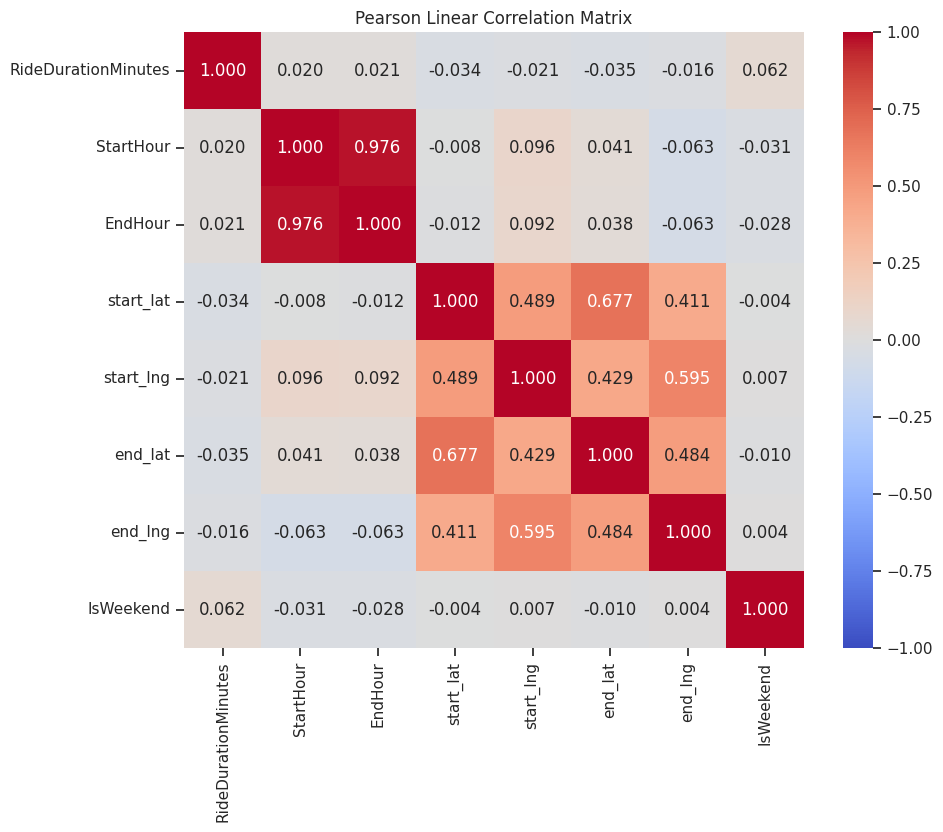

In [ ]:
# Visualize Pearson Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(pearson_matrix, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Pearson Linear Correlation Matrix')
plt.show()

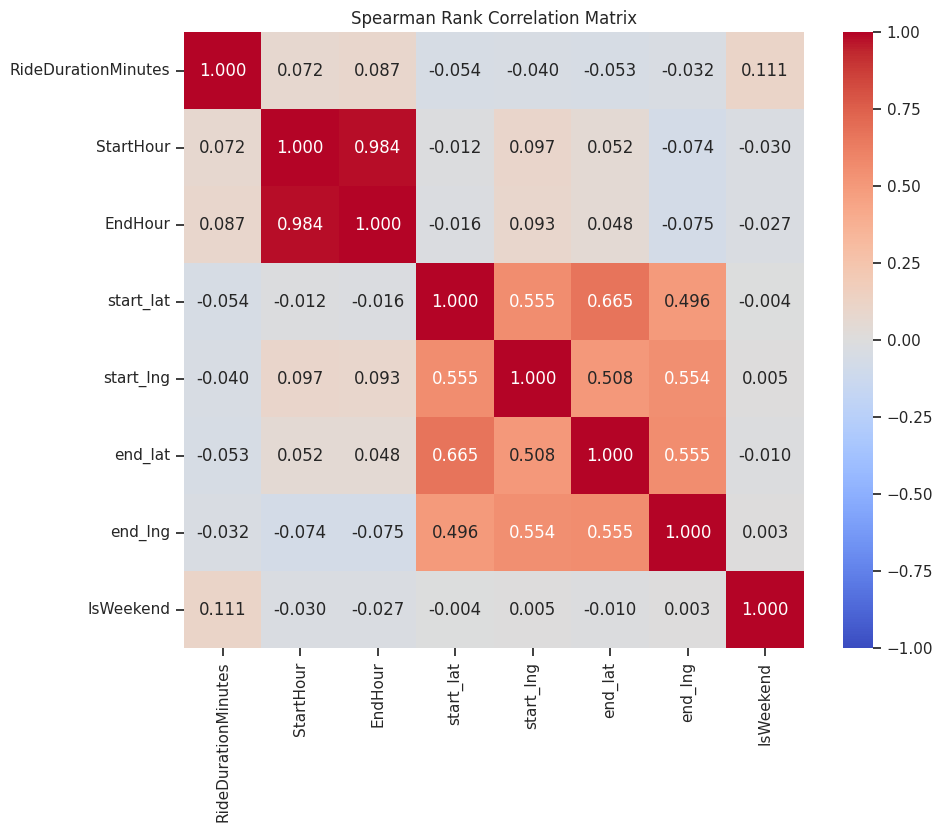

In [ ]:
# Visualize Spearman Rank Correlation Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(spearman_matrix, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Spearman Rank Correlation Matrix')
plt.show()

In [ ]:
# Selected Pearson and Spearman tests with pairwise N and p-values.
# With a large dataset, p-values can be tiny even for practically small correlations.
selected_pairs = [
    ('StartHour', 'RideDurationMinutes'),
    ('IsWeekend', 'RideDurationMinutes'),
    ('start_lat', 'RideDurationMinutes'),
    ('start_lng', 'RideDurationMinutes')
]
test_rows = []
for x_col, y_col in selected_pairs:
    pair_data = df_clean[[x_col, y_col]].dropna()
    n = len(pair_data)
    if n >= 3:
        pearson_r, pearson_p = stats.pearsonr(pair_data[x_col], pair_data[y_col])
        spearman_r, spearman_p = stats.spearmanr(pair_data[x_col], pair_data[y_col])
        test_rows.extend([
            {'X': x_col, 'Y': y_col, 'Method': 'Pearson', 'N': n, 'Correlation': pearson_r, 'p_value': pearson_p},
            {'X': x_col, 'Y': y_col, 'Method': 'Spearman', 'N': n, 'Correlation': spearman_r, 'p_value': spearman_p}
        ])
test_results = pd.DataFrame(test_rows)
display(test_results)

print("Interpretation notes:")
print("- Correlation is association, not causation.")
print("- A small p-value does not imply a practically strong relationship.")
print("- Several tested pairs increase the chance of false positives; treat these selected tests as exploratory.")
print("- Clock hour is cyclic (23:00 is close to 00:00), so raw StartHour/EndHour correlations have limitations.")
print("- Latitude/longitude are spatial coordinates, not direct measures of route distance.")


,X,Y,Method,N,Correlation,p_value
0,StartHour,RideDurationMinutes,Pearson,439922,0.019866,1.179025e-39
1,StartHour,RideDurationMinutes,Spearman,439922,0.072164,0.000000e+00
2,IsWeekend,RideDurationMinutes,Pearson,439922,0.062183,0.000000e+00
3,IsWeekend,RideDurationMinutes,Spearman,439922,0.110910,0.000000e+00
4,start_lat,RideDurationMinutes,Pearson,439922,-0.033546,9.865880e-110
5,start_lat,RideDurationMinutes,Spearman,439922,-0.054295,2.075293e-284
6,start_lng,RideDurationMinutes,Pearson,439922,-0.021072,2.118676e-44
7,start_lng,RideDurationMinutes,Spearman,439922,-0.039639,1.832213e-152


Interpretation notes:
- Correlation is association, not causation.
- A small p-value does not imply a practically strong relationship.
- Several tested pairs increase the chance of false positives; treat these selected tests as exploratory.
- Clock hour is cyclic (23:00 is close to 00:00), so raw StartHour/EndHour correlations have limitations.
- Latitude/longitude are spatial coordinates, not direct measures of route distance.


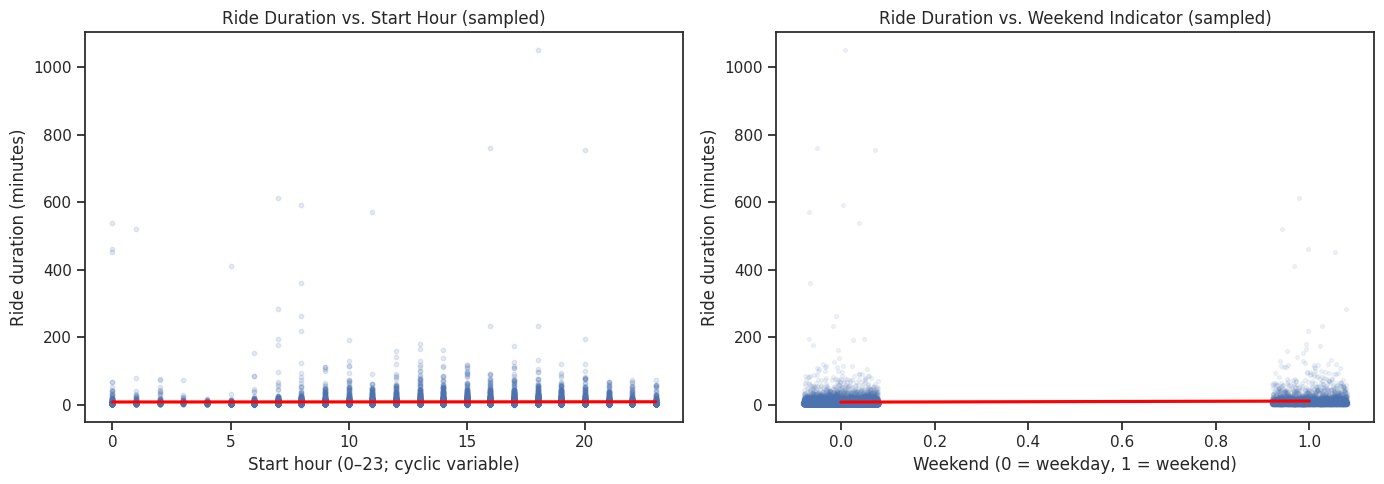

In [ ]:
# Selected scatterplots with linear trend lines. Sampling keeps plots readable.
plot_df = df_clean[['RideDurationMinutes', 'StartHour', 'IsWeekend']].dropna()
if len(plot_df) > 20000:
    plot_df = plot_df.sample(20000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=plot_df, x='StartHour', y='RideDurationMinutes',
            scatter_kws={'alpha': 0.15, 's': 10}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('Ride Duration vs. Start Hour (sampled)')
axes[0].set_xlabel('Start hour (0–23; cyclic variable)')
axes[0].set_ylabel('Ride duration (minutes)')

sns.regplot(data=plot_df, x='IsWeekend', y='RideDurationMinutes',
            x_jitter=0.08, scatter_kws={'alpha': 0.08, 's': 8},
            line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title('Ride Duration vs. Weekend Indicator (sampled)')
axes[1].set_xlabel('Weekend (0 = weekday, 1 = weekend)')
axes[1].set_ylabel('Ride duration (minutes)')
plt.tight_layout()
plt.show()


## Part 7: Multiple Linear Regression

Now we will build a multiple linear regression model to predict `RideDurationMinutes` using trip features such as start hour (cyclical components), weekend status, rider type, and bike type.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Target and predictors are deliberately separate; duration-derived fields are not predictors.
predictors = ['StartHour_sin', 'StartHour_cos', 'IsWeekend', 'member_casual', 'rideable_type']
target = 'RideDurationMinutes'
df_reg = df_clean[predictors + [target]].dropna().copy()

# One-hot encoding with drop_first=True: reference categories are the first sorted levels
# (normally casual and classic_bike for these two binary variables).
df_encoded = pd.get_dummies(
    df_reg, columns=['member_casual', 'rideable_type'], drop_first=True, dtype=int
)
X = df_encoded.drop(columns=[target])
y = df_encoded[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Baseline: predict the training-set mean for every test observation.
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_metrics = {
    'R²': r2_score(y_test, baseline_pred),
    'MAE (minutes)': mean_absolute_error(y_test, baseline_pred),
    'RMSE (minutes)': np.sqrt(mean_squared_error(y_test, baseline_pred))
}

print("=== Multiple Linear Regression: held-out test set ===")
print(f"Test rows: {len(y_test):,}")
print(f"R²:   {r2:.4f}")
print(f"MAE:  {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print("\n=== Mean-baseline comparison ===")
display(pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Training-mean baseline'],
    'R²': [r2, baseline_metrics['R²']],
    'MAE (minutes)': [mae, baseline_metrics['MAE (minutes)']],
    'RMSE (minutes)': [rmse, baseline_metrics['RMSE (minutes)']]
}))

print("\nReference categories and coefficient interpretation:")
print("- Omitted rider reference category: casual, if the encoded levels are casual/member.")
print("- Omitted bike reference category: classic_bike, if the encoded levels are classic_bike/electric_bike.")
print("- Coefficients are conditional associations holding the other included predictors fixed; they do not establish causation.")
print("- R² measures variance explained on this test split. Low R² indicates limited predictive performance for this feature set.")


=== Multiple Linear Regression: held-out test set ===
Test rows: 87,985
R²:   0.0329
MAE:  5.83 minutes
RMSE: 18.84 minutes

=== Mean-baseline comparison ===


,Model,R²,MAE (minutes),RMSE (minutes)
0,Multiple Linear Regression,0.03285,5.830278,18.843758
1,Training-mean baseline,-0.00006,5.966002,19.161688



Reference categories and coefficient interpretation:
- Omitted rider reference category: casual, if the encoded levels are casual/member.
- Omitted bike reference category: classic_bike, if the encoded levels are classic_bike/electric_bike.
- Coefficients are conditional associations holding the other included predictors fixed; they do not establish causation.
- R² measures variance explained on this test split. Low R² indicates limited predictive performance for this feature set.


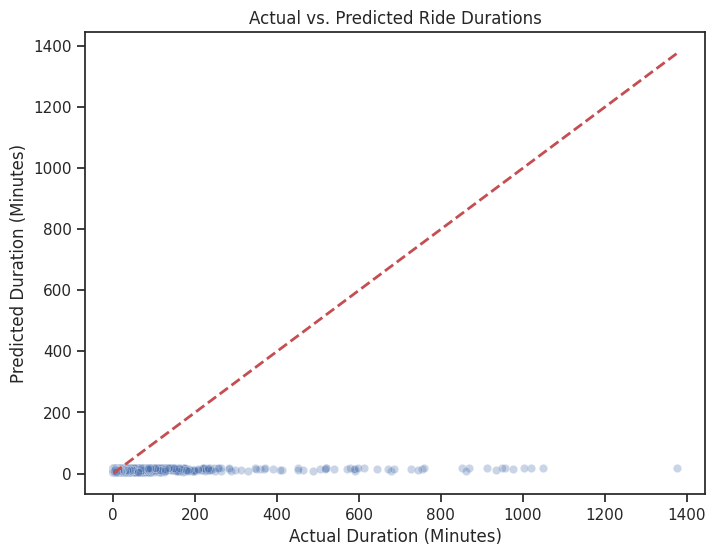

In [ ]:
# 5. Plot Actual vs Predicted Trip Durations
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs. Predicted Ride Durations')
plt.xlabel('Actual Duration (Minutes)')
plt.ylabel('Predicted Duration (Minutes)')
plt.show()

In [ ]:
# 6. Print Coefficients with Reference Category Explanations
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
print("=== Regression Coefficients (Reference Categories: member_casual_casual, rideable_type_classic_bike) ===")
display(coefficients)

=== Regression Coefficients (Reference Categories: member_casual_casual, rideable_type_classic_bike) ===


,Feature,Coefficient
0,StartHour_sin,-0.848542
1,StartHour_cos,-0.477210
2,IsWeekend,2.220223
3,member_casual_member,-6.722790
4,rideable_type_electric_bike,-3.837349


## Part 8: Model Evaluation and Residual Analysis

Evaluate held-out predictions, compare against a simple baseline, and inspect residual patterns. Metrics are recalculated when the notebook is run.

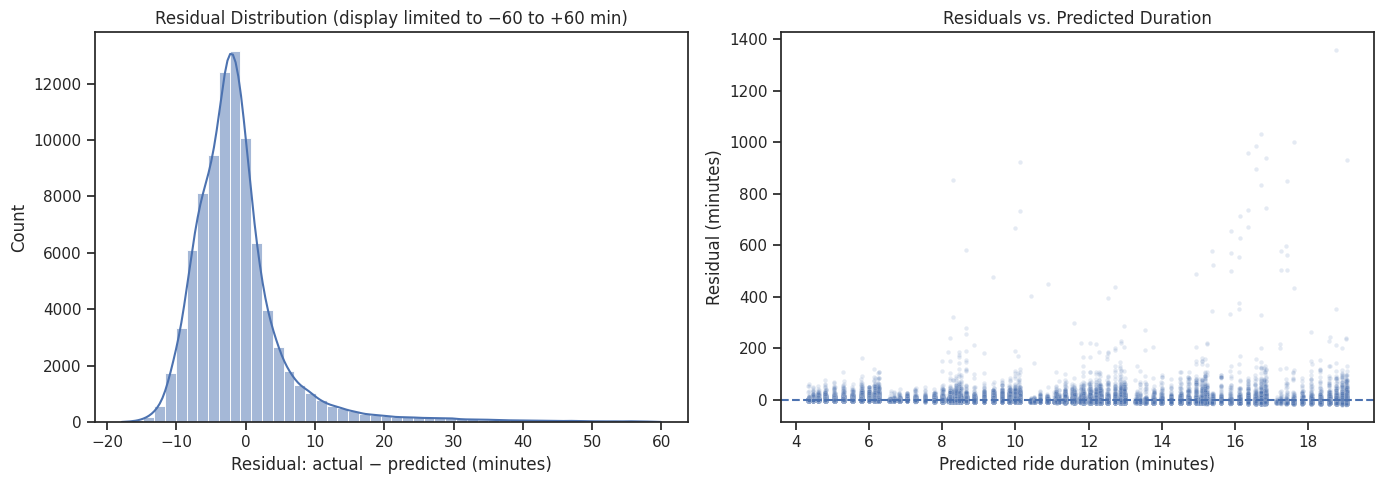

Residual min: -17.88 min; max: 1357.69 min
Test target median: 5.80 min; 95th percentile: 22.67 min
Because ride duration is right-skewed, RMSE is especially sensitive to large misses. The truncated histogram is for readability only; metrics above use all test rows.


In [ ]:
# Residual diagnostics on the held-out test set.
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Show central residual distribution clearly; report the full range separately.
sns.histplot(residuals[residuals.between(-60, 60)], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Residual Distribution (display limited to −60 to +60 min)')
axes[0].set_xlabel('Residual: actual − predicted (minutes)')
axes[0].set_ylabel('Count')

sns.scatterplot(x=y_pred, y=residuals, alpha=0.15, s=10, ax=axes[1])
axes[1].axhline(0, linestyle='--')
axes[1].set_title('Residuals vs. Predicted Duration')
axes[1].set_xlabel('Predicted ride duration (minutes)')
axes[1].set_ylabel('Residual (minutes)')
plt.tight_layout()
plt.show()

print(f"Residual min: {residuals.min():.2f} min; max: {residuals.max():.2f} min")
print(f"Test target median: {y_test.median():.2f} min; 95th percentile: {y_test.quantile(0.95):.2f} min")
print("Because ride duration is right-skewed, RMSE is especially sensitive to large misses. The truncated histogram is for readability only; metrics above use all test rows.")


## Part 9: Final Conclusion

The conclusion below is generated from the current run's computed values. Interpret the findings as associations and predictions, not causal evidence.

In [ ]:
# Final summary based on the current notebook execution.
print("=== Final Conclusion (computed from this run) ===")
print(f"Raw records: {len(df_raw):,}")
print(f"Final cleaned records: {len(df_clean):,}")
print(f"Rows excluded overall: {len(df_raw) - len(df_clean):,}")
print(f"Rows removed by global coordinate-range validation: {invalid_coordinate_rows:,}")
print(f"Exact duplicate rows in raw data: {int(df_raw.duplicated().sum()):,}")
print(f"Repeated ride_id rows in raw data: {int(df_raw.duplicated(subset=['ride_id']).sum()):,}")
print(f"Non-positive duration rows counted before duration filtering: {non_positive_count:,}")
print(f">24-hour duration rows counted before duration filtering: {exceed_24h_count:,}")
print("\\nStation recovery attempts (values recovered before later filters):")
for operation, count in station_recovery_counts.items():
    print(f"- {operation}: {count:,}")
print("\\nRecovered values retained in the final dataset:")
for column, count in station_recovery_counts_final.items():
    if count:
        print(f"- {column}: {count:,}")
dropna_removed = cleaning_log_df.loc[
    cleaning_log_df['Step'].eq('Drop rows with unresolved missing values after station recovery'),
    'Rows Removed'
].sum()
print(f"Rows dropped by final dropna after recovery: {int(dropna_removed):,}")
print(f"Selected correlation: StartHour vs duration, Pearson r = {df_clean['StartHour'].corr(df_clean['RideDurationMinutes']):.4f}")
print(f"Selected correlation: IsWeekend vs duration, Pearson r = {df_clean['IsWeekend'].corr(df_clean['RideDurationMinutes']):.4f}")
print(f"Regression test metrics: R² = {r2:.4f}, MAE = {mae:.2f} min, RMSE = {rmse:.2f} min")
print("\\nInterpretation:")
print("- Station IDs/names and coordinates were recovered only from unique mappings supported by other records; ambiguous matches were not guessed.")
print("- After recovery attempts, dropna removed rows with unresolved missing values. The cleaning log records the exact row effect and each recovery count.")
print("- The duration cutoff removes non-positive trips and trips longer than 24 hours; the comparison table shows how the >24-hour rule changes duration summaries and a selected correlation.")
print("- Pearson captures linear association; Spearman captures monotonic rank association. With a large sample, statistical significance can coexist with a small effect.")
print("- The regression model's performance must be judged against the mean baseline and its test metrics. Low R² means the included temporal and categorical features explain only a small share of duration variability.")
print("- Duration is right-skewed and RMSE is sensitive to large errors. Residual plots help diagnose misspecification, but this model does not establish causal effects.")


=== Final Conclusion (computed from this run) ===
Raw records: 441,063
Final cleaned records: 439,922
Rows excluded overall: 1,141
Rows removed by global coordinate-range validation: 0
Exact duplicate rows in raw data: 0
Repeated ride_id rows in raw data: 0
Non-positive duration rows counted before duration filtering: 0
>24-hour duration rows counted before duration filtering: 132
\nStation recovery attempts (values recovered before later filters):
- start_id_from_unique_name: 0
- end_id_from_unique_name: 225
- start_name_from_unique_id: 0
- end_name_from_unique_id: 0
- start_station_fields_from_exact_coordinates: 0
- end_station_fields_from_exact_coordinates: 0
- start_station_fields_from_unique_rounded_coordinates: 0
- end_station_fields_from_unique_rounded_coordinates: 132
- start_coordinates_from_unique_station_id: 0
- end_coordinates_from_unique_station_id: 136
\nRecovered values retained in the final dataset:
- end_station_name: 65
- end_station_id: 290
- end_lat: 68
- end_lng: 6